In [128]:
import numpy as np
import random

In [129]:
# Model parameters
n = 101                  # Number of customers and possible positions
D = 1.0                  # Total demand
p = 1.0                  # Same price for both firms

demand_per_customer = D / n  # Demand per customer

# Discrete road and customers
road = np.linspace(-1, 1, n)

"""Calculate each firm's market share."""
"""Calculate the firms' profits."""
"""Choose the best nearby position for a firm."""

# If profits are equal, the firm stays in its current position

# Initial positions
x1 = random.choice(road)
x2 = random.choice(road)

# Iterative local adjustment

# Firm 1 adjusts its position
# Firm 2 adjusts its position


""" print(f"Number of iterations: {iteration + 1}")
print(f"Firm 1 final position: {position_1:.2f}")
print(f"Firm 2 final position: {position_2:.2f}")
print(f"Firm 1 profit: {profit_1:.3f}")
print(f"Firm 2 profit: {profit_2:.3f}") """

# Show changes in the firms' positions

' print(f"Number of iterations: {iteration + 1}")\nprint(f"Firm 1 final position: {position_1:.2f}")\nprint(f"Firm 2 final position: {position_2:.2f}")\nprint(f"Firm 1 profit: {profit_1:.3f}")\nprint(f"Firm 2 profit: {profit_2:.3f}") '

In [130]:
# Count customers assigned to each firm and calculate profits as 
# number of customers * demand per customer

def calculate_profit(x1, x2):
    distance_to_1 = np.abs(road - x1)
    distance_to_2 = np.abs(road - x2)

    number_customers_1 = np.sum(distance_to_1 < distance_to_2)
    number_customers_2 = np.sum(distance_to_2 < distance_to_1)

    return number_customers_1 * demand_per_customer, number_customers_2 * demand_per_customer

In [131]:
# Calculate whether the firm's profit would increase by moving to an adjacent position (on the road), 
# holding the other firm's position constant
def best_adjacent_position(current_position, other_firm_position):
    current_index = np.where(road == current_position)[0][0]
    best_position = current_position
    best_profit = calculate_profit(current_position, other_firm_position)[0]

    # Check left adjacent position
    if current_index > 0:
        left_position = road[current_index - 1]
        left_profit = calculate_profit(left_position, other_firm_position)[0]
        if left_profit > best_profit:
            best_profit = left_profit
            best_position = left_position

    # Check right adjacent position
    if current_index < len(road) - 1:
        right_position = road[current_index + 1]
        right_profit = calculate_profit(right_position, other_firm_position)[0]
        if right_profit > best_profit:
            best_profit = right_profit
            best_position = right_position

    return best_position

In [132]:
# Profit calculation including equal distance
def calculate_profit(x1, x2):
    d1 = np.abs(road - x1)
    d2 = np.abs(road - x2)

    customers_1 = np.sum(d1 < d2) + 0.5 * np.sum(np.isclose(d1, d2))
    customers_2 = np.sum(d2 < d1) + 0.5 * np.sum(np.isclose(d1, d2))

    return p * customers_1 * demand_per_customer, p * customers_2 * demand_per_customer


# Save positions
history_1 = [x1]
history_2 = [x2]


# Continue until neither firm wants to move
for iteration in range(1000):
    old_x1, old_x2 = x1, x2

    x1 = best_adjacent_position(old_x1, old_x2)
    x2 = best_adjacent_position(old_x2, old_x1)

    history_1.append(x1)
    history_2.append(x2)

    if np.isclose(x1, old_x1) and np.isclose(x2, old_x2):
        break

profit_1, profit_2 = calculate_profit(x1, x2)

print(f"Number of iterations: {iteration + 1}")
print(f"Firm 1 final position: {x1:.2f}")
print(f"Firm 2 final position: {x2:.2f}")
print(f"Firm 1 profit: {profit_1:.3f}")
print(f"Firm 2 profit: {profit_2:.3f}")

Number of iterations: 50
Firm 1 final position: 0.00
Firm 2 final position: 0.00
Firm 1 profit: 0.500
Firm 2 profit: 0.500


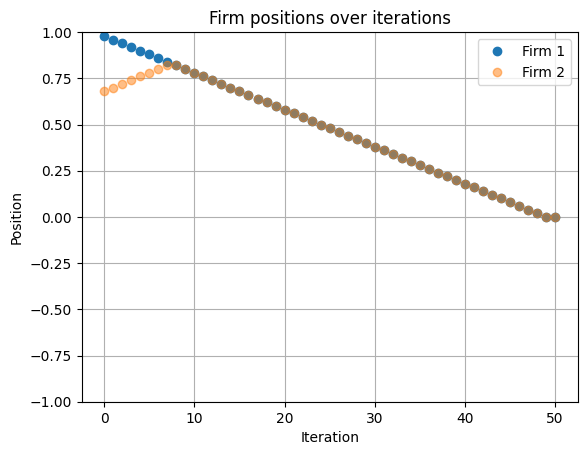

In [133]:
import matplotlib.pyplot as plt

plt.plot(history_1, marker="o", linestyle="None", label="Firm 1")
plt.plot(history_2, marker="o", linestyle="None", label="Firm 2", alpha=0.5)

plt.xlabel("Iteration")
plt.ylabel("Position")
plt.title("Firm positions over iterations")
plt.ylim(-1, 1)
plt.legend()
plt.grid()

plt.show()